# Spatio-temporal Transcriptomics with Negative Binomial likelihood

In [1]:

import numpy as np
import torch

from torch.nn import Parameter
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
from pathlib import Path
from scipy.interpolate import interp1d

from torch.optim import Adam
from gpytorch.optim import NGD

from alfi.models import TrainMode, MultiOutputGP, PartialLFM, generate_multioutput_gp
from alfi.impl.pdes import ReactionDiffusion
from alfi.utilities.data import dros_ground_truth
from alfi.utilities.fenics import interval_mesh
from alfi.datasets import DrosophilaSpatialTranscriptomics, HomogeneousReactionDiffusion
from alfi.trainers import PartialPreEstimator, PDETrainer
from alfi.plot import plot_spatiotemporal_data, Plotter1d
from alfi.utilities.torch import softplus, inv_softplus
from alfi.configuration import VariationalConfiguration


/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
def identity(x):
    return x

In [3]:
import gpytorch
import math

class NBGaussian:
    def __init__(self, gaussian_dist, nb_likelihood):
        """
        Initialize the NB-GP distribution with a GP model and a Negative Binomial likelihood.

        Args:
            gp_model: A GPyTorch Multivariate Gaussian.
            nb_likelihood: A Negative Binomial likelihood instance from alfi.likelihood.negative_binomial.
        """
        self.gaussian_dist = gaussian_dist
        self.nb_likelihood = nb_likelihood

    def mean(self):
        """
        Compute the mean of the NB-GP distribution.

        Args:
            tx: Input tensor of shape (2, N), where N is the number of data points.

        Returns:
            The mean of the predictive distribution.
        """
        predictive_mean = self.gaussian_dist.mean
        return predictive_mean 

    def var(self, tx):
        """
        Compute the variance of the NB-GP distribution.

        Args:
            tx: Input tensor of shape (2, N), where N is the number of data points.

        Returns:
            The variance of the predictive distribution elementwise.
        """
        part_one = self.gaussian_dist.covariance_matrix # TODO check whether this returns a covariance matrix
        part_two = torch.diag(self.mean())
        part_three = self.nb_likelihood.alpha * torch.diag(self.diag(part_one) + self.mean()**2)
        return torch.diag(part_one + part_two + part_three)

    def sample(self, num_samples=1):
        """
        Generate samples from the NB-GP distribution.

        Args:
            tx: Input tensor of shape (2, N), where N is the number of data points.
            num_samples: Number of samples to generate.

        Returns:
            Samples from the predictive distribution.
        """
        # TODO check shape of sampels
        
        with torch.no_grad():
            # Sample from the Gaussian distribution
            sample_per_layer = math.ceil(math.sqrt(num_samples))
            h_mean_sample = self.gaussian_dist.sample(torch.Size([sample_per_layer])) # TODO check shape
            alpha = self.nb_likelihood.alpha
            link = self.nb_likelihood.invlink
            r = 1 / alpha
            p =1 - (r / (r + link(h_mean_sample)))
            p = torch.clamp(p, min=1e-6, max=1 - 1e-6)  # Ensure p is in (0, 1)
            
            nb_dist = gpytorch.distributions.base_distributions.NegativeBinomial(
                total_count=r,
                probs=p,
            )
            h_samples = nb_dist.sample(torch.Size([sample_per_layer]))
            # TODO reshape h_samples

            return h_samples

In [4]:
from alfi.likelihood.negative_binomial import NegativeBinomialLikelihood
from alfi.mlls import MaskedVariationalELBO
# TODO change lfm.config.num_samples will change nb_likelihood.num_likelihood_samples
class NegativeBinomialPartialLFM(PartialLFM):
    def __init__(self, *args, nb_initial_alpha=0.2, nb_scale=1.0, nb_learnable_alpha=True, **kwargs):
        super().__init__(*args, **kwargs)
        self.likelihood = NegativeBinomialLikelihood(alpha=nb_initial_alpha, invlink=identity, scale=nb_scale, learnable_alpha=nb_learnable_alpha)
        self.likelihood.double()
        if kwargs["num_training_points"] is None:
            num_training_points = self.inducing_points.numel()
        else:
            num_training_points = kwargs["num_training_points"]
        self.loss_fn = MaskedVariationalELBO(self.likelihood, self.gp_model, num_training_points, combine_terms=False)

    def predict_m(self, tx, **kwargs):
        h_mean = self(tx)
        return NBGaussian(
            gaussian_dist=h_mean,
            nb_likelihood=self.likelihood
        )
    
    def G(self, u):
        return softplus(u)
        
    

## Import other modules

In [5]:
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']


In [ ]:
### Load data and configuration
drosophila = True
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if drosophila:
    gene = 'kr'
    dataset = DrosophilaSpatialTranscriptomics(
        gene=gene, data_dir='./data', scale=True, disc=20) # data folder
    params = dict(lengthscale=10,
                  **dros_ground_truth(gene),
                  parameter_grad=False,
                  warm_epochs=-1,
                  natural=True,
                  zero_mean=True,
                  clamp=True)
    disc = dataset.disc
else:
    data = 'toy-spatial'
    dataset = HomogeneousReactionDiffusion(data_dir='./data')
    params = dict(lengthscale=0.2,
                  sensitivity=1,
                  decay=0.1,
                  diffusion=0.01,
                  warm_epochs=-1,
                  dp=0.025,
                  natural=True,
                  clamp=False)
    disc = 1

data = next(iter(dataset))
tx, y_target = data
lengthscale = params['lengthscale']
zero_mean = params['zero_mean'] if 'zero_mean' in params else False


Matching: True
tx torch.Size([2, 1681])
torch.Size([1, 840, 2])
(0.0, 1.0)


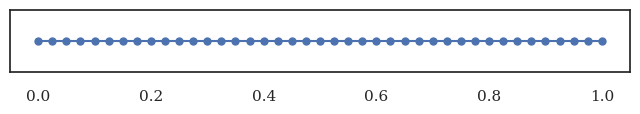

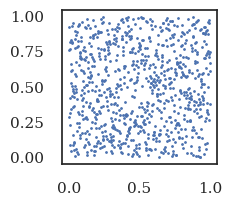

In [7]:
from dolfin import *
# We calculate a mesh that contains all possible spatial locations in the dataset

spatial = np.unique(tx[1, :])
mesh = interval_mesh(spatial)
plot(mesh)
# The mesh coordinates should match up to the data:
print('Matching:', (spatial == mesh.coordinates().reshape(-1)).all())
### Set up GP model
# Define GP
if tx.shape[1] > 1000:
    num_inducing = int(tx.shape[1] * 3/6)
else:
    num_inducing = int(tx.shape[1] * 5/6)
use_lhs = True
# whether inducing points should be sampled using LHS or random choice
if use_lhs:
    print('tx', tx.shape)
    from smt.sampling_methods import LHS
    ts = tx[0, :].unique().sort()[0].numpy()
    xs = tx[1, :].unique().sort()[0].numpy()
    xlimits = np.array([[ts[0], ts[-1]],[xs[0], xs[-1]]])
    sampling = LHS(xlimits=xlimits, random_state=np.random.RandomState(SEED))
    inducing_points = torch.tensor(sampling(num_inducing)).unsqueeze(0)
else:
    inducing_points = torch.stack([
        tx[0, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]],
        tx[1, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]]
    ], dim=1).unsqueeze(0)
gp_kwargs = dict(learn_inducing_locations=False,
                 natural=params['natural'],
                 use_tril=True)

gp_model = generate_multioutput_gp(
    1, inducing_points,
    initial_lengthscale=lengthscale,
    ard_dims=2,
    zero_mean=zero_mean,
    gp_kwargs=gp_kwargs)
gp_model.covar_module.lengthscale = lengthscale
# lengthscale_constraint=Interval(0.1, 0.3),
gp_model.double()

print(inducing_points.shape)
plt.figure(figsize=(2, 2))
plt.scatter(inducing_points[0,:,0], inducing_points[0, :, 1], s=1)
### Set up PDE (fenics module)
# Define fenics model
ts = tx[0, :].unique().sort()[0].numpy()
t_range = (ts[0], ts[-1])
print(t_range)
time_steps = dataset.num_discretised
fenics_model = ReactionDiffusion(t_range, time_steps, mesh)

config = VariationalConfiguration(
    initial_conditions=False,
    num_samples=5
)


In [8]:
## Set up the LFM

# Define LFM
parameter_grad = params['parameter_grad'] if 'parameter_grad' in params else True
sensitivity = Parameter(
    inv_softplus(torch.tensor(params['sensitivity'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=False)
decay = Parameter(
    inv_softplus(torch.tensor(params['decay'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)
diffusion = Parameter(
    inv_softplus(torch.tensor(params['diffusion'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)

fenics_params = [sensitivity, decay, diffusion]

train_ratio = 0.3
num_training = int(train_ratio * tx.shape[1])

lfm = NegativeBinomialPartialLFM(1, gp_model, fenics_model, fenics_params, config, num_training_points=num_training)
if params['natural']:
    variational_optimizer = NGD(lfm.variational_parameters(), num_data=num_training, lr=0.015)
    parameter_optimizer = Adam(lfm.nonvariational_parameters(), lr=0.015)
    optimizers = [variational_optimizer, parameter_optimizer]
else:
    optimizers = [Adam(lfm.parameters(), lr=0.005)]

track_parameters = list(lfm.fenics_named_parameters.keys()) +\
                   list(map(lambda s: f'gp_model.{s}', dict(lfm.gp_model.named_hyperparameters()).keys()))

# As in Lopez-Lopera et al., we take 30% of data for training
train_mask = torch.zeros_like(tx[0, :])
train_mask[torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:int(train_ratio * tx.shape[1])]] = 1

orig_data = dataset.orig_data.squeeze().t()
trainer = PDETrainer(lfm, optimizers, dataset,
                     clamp=params['clamp'],
                     track_parameters=track_parameters,
                     train_mask=train_mask.bool(),
                     warm_variational=-1,
                     lf_target=orig_data)
# trainer.tx is tx from the dataset, added with discreti
tx = trainer.tx
num_t_orig = orig_data[:, 0].unique().shape[0]
num_x_orig = orig_data[:, 1].unique().shape[0]
num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]

ts = tx[0, :].unique().sort()[0].numpy()
xs = tx[1, :].unique().sort()[0].numpy()
extent = [ts[0], ts[-1], xs[0], xs[-1]] # limits on the x-axis and t-axis
# NOTE can be skipped
# print(num_t_orig, num_x_orig, num_t, num_x)
print(dataset.disc)
print(dataset.num_discretised)


x dp is set to tensor(0.0250, dtype=torch.float64)
1
40


/var/folders/75/bxpz0dmj2f54jdmkxsc585340000gp/T/ipykernel_95480/1742730316.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


torch.Size([41, 41])
torch.Size([1, 1])
num_t 41 num_x 41
num_t_orig: 41, num_x_orig: 41
torch.Size([1, 1681])


/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/torchcubicspline/interpolate.py:277: UserWarning: torch.searchsorted(): boundary tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous boundary tensor if possible. This message will only appear once per program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/BucketizationUtils.h:40.)
  index = torch.bucketize(t.detach(), self._t) - 1


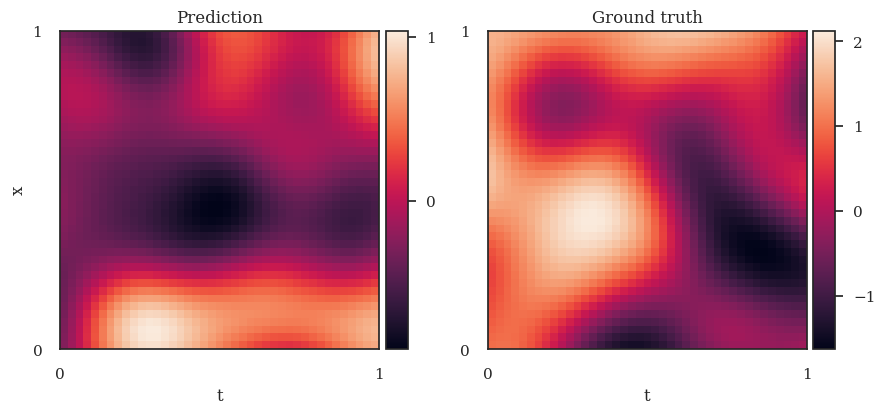

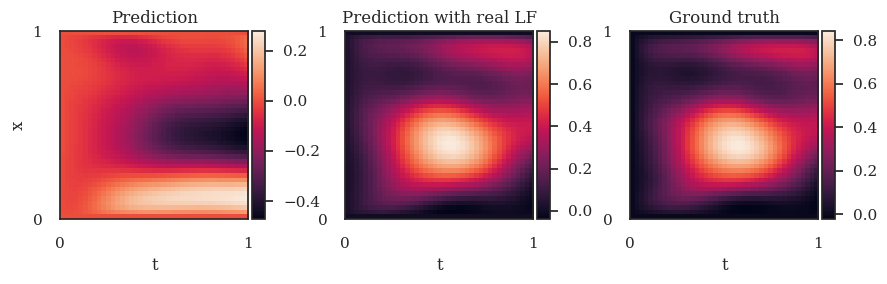

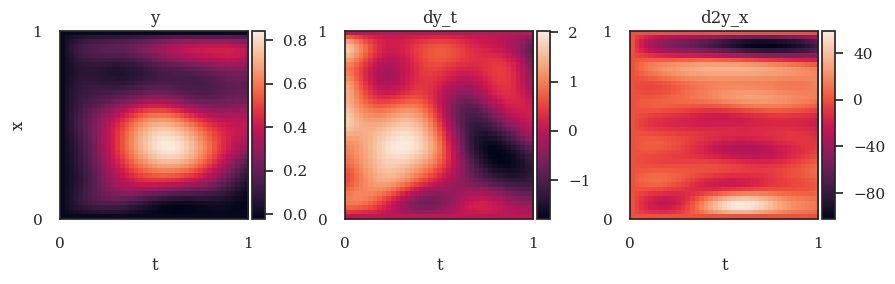

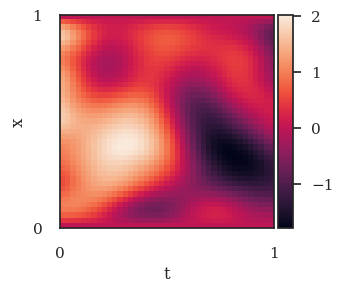

In [9]:
#### Generate output from GP prior and LFM given true/predicted latent

time = orig_data[:, 0].unique()
latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)
latent = latent.repeat(lfm.config.num_samples, 1, 1)
latent = latent.view(lfm.config.num_samples, 1, num_t_orig, num_x_orig)
time_interp = tx[0].unique()
time_interp[-1] -= 1e-5 
latent = torch.from_numpy(interp1d(time, latent, axis=2)(time_interp))

# NOTE can be skipped
# without any training, using the prior of the GP
# gp_model.covar_module.lengthscale = 0.3*0.3 * 2
out = gp_model(trainer.tx.transpose(0, 1))
sample = out.sample(torch.Size([lfm.config.num_samples])).permute(0, 2, 1)
plot_spatiotemporal_data(
    [
        sample.mean(0)[0].detach().view(num_t, num_x).t(),
        latent[0].squeeze().view(num_t, num_x).t(),
    ],
    extent,
    titles=['Prediction', 'Ground truth']
)
sample = sample.view(lfm.config.num_samples, 1, num_t, num_x)

output_pred = lfm.solve_pde(sample).mean(0)
output = lfm.solve_pde(latent).mean(0)
# NOTE can be skipped
print(output.shape)
plot_spatiotemporal_data(
    [
        output_pred.squeeze().detach().t(),
        output.squeeze().detach().t(),
        trainer.y_target.view(num_t_orig, num_x_orig).t()
    ],
    extent,
    titles=['Prediction', 'Prediction with real LF', 'Ground truth']
)
print(sensitivity.shape)
num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]
print('num_t', num_t, 'num_x', num_x)
y_target = trainer.y_target[0]
y_matrix = y_target.view(num_t_orig, num_x_orig)

pde_func, pde_target = lfm.fenics_model.interpolated_gradient(tx, y_matrix, disc=disc, plot=True)
# pde_func(y, u, sensitivity, decay, diffusion)
# pde_target = dy_t interpolated
u = orig_data[trainer.t_sorted, 2].view(num_t_orig, num_x_orig)
print(f"num_t_orig: {num_t_orig}, num_x_orig: {num_x_orig}")
u = u.view(1, -1)
print(u.shape)
# NOTE can be skipped
plot_spatiotemporal_data([pde_target.view(num_t_orig, num_x_orig).t()],
                         extent=extent, figsize=(3,3))


## Sample from NB distribution

In [10]:
h_mean = lfm(tx)
nb_dist = NBGaussian(
    gaussian_dist=h_mean,
    nb_likelihood=lfm.likelihood
)
# Apply sigmoid to constrain probs to [0, 1]
nb_dist.nb_likelihood.invlink = torch.sigmoid
nb_dist.sample(num_samples=36)

tensor([[[[3.],
          [1.],
          [0.],
          ...,
          [0.],
          [0.],
          [0.]],

         [[1.],
          [0.],
          [0.],
          ...,
          [0.],
          [0.],
          [1.]],

         [[0.],
          [4.],
          [1.],
          ...,
          [0.],
          [0.],
          [0.]],

         [[0.],
          [0.],
          [0.],
          ...,
          [2.],
          [0.],
          [0.]],

         [[0.],
          [0.],
          [0.],
          ...,
          [2.],
          [0.],
          [1.]],

         [[0.],
          [1.],
          [2.],
          ...,
          [0.],
          [0.],
          [3.]]],


        [[[1.],
          [0.],
          [0.],
          ...,
          [0.],
          [0.],
          [1.]],

         [[2.],
          [1.],
          [0.],
          ...,
          [0.],
          [0.],
          [0.]],

         [[3.],
          [2.],
          [1.],
          ...,
          [2.],
          [0.],

In [ ]:

train_ratio = 0.3
num_training = int(train_ratio * tx.shape[1])
print(num_training)
if params['natural']:
    variational_optimizer = NGD(lfm.variational_parameters(), num_data=num_training, lr=0.03)
    parameter_optimizer = Adam(lfm.nonvariational_parameters(), lr=0.03)
    optimizers = [variational_optimizer, parameter_optimizer]
else:
    optimizers = [Adam(lfm.parameters(), lr=0.05)]


pre_estimator = PartialPreEstimator(
    lfm, optimizers, dataset, pde_func,
    input_pair=(trainer.tx, trainer.y_target), target=pde_target,
    train_mask=trainer.train_mask
)
import time
t0 = time.time()
lfm.set_mode(TrainMode.GRADIENT_MATCH)
lfm.config.num_samples = 50
# TODO change this to 80 later
times = pre_estimator.train(60, report_interval=5)
lfm.config.num_samples = 5
print(tx.shape)
tx_orig = orig_data[:, :2].t()
print(tx_orig.shape)

# Compare tx and tx_orig, find the indices of tx that correspond to tx_orig
indices = torch.where(torch.all(torch.eq(tx.unsqueeze(-1), tx_orig.unsqueeze(1)), dim=0))[1]
print(tx[:, indices])
print(tx_orig[:, indices])
# the first 512 points of tx correspond to tx_orig
from alfi.utilities.torch import q2, cia
lfm.eval()
# f = lfm(tx)
f = lfm(tx)
f_mean = f.mean.detach()[:512]
f_var = f.variance.detach()[:512]
y_target = trainer.y_target[0]
# TODO find tx corresponding to y_target
print(y_target.shape)
print(tx.shape)

print(f_mean.shape, y_target.shape, f_var.shape)
print('prot Q2', q2(y_target.squeeze(), f_mean.squeeze()))
print('prot CA', cia(y_target.squeeze(), f_mean.squeeze(), f_var.squeeze()))
gp = lfm.gp_model(tx.t())
lf_target = orig_data[trainer.t_sorted, 2]
f_mean = gp.mean.detach().view(num_t, num_x)[::disc].reshape(-1)
f_var = gp.variance.detach().view(num_t, num_x)[::disc].reshape(-1)

print('mrna Q2', q2(lf_target.squeeze(), f_mean.squeeze()))
print('mrna CA', cia(lf_target.squeeze(), f_mean.squeeze(), f_var.squeeze()))


# print(np.stack(times).shape)
# plt.plot(np.stack(times)[:, 1])
print(f.variance.detach())
print(lfm.likelihood.noise)


504


ValueError: Expected value argument (Tensor of shape (1681, 1)) to be within the support (IntegerGreaterThan(lower_bound=0)) of the distribution NegativeBinomial(total_count: torch.Size([20, 1681, 1]), probs: torch.Size([20, 1681, 1])), but found invalid values:
tensor([[ 0.0000e+00],
        [ 4.1748e-01],
        [ 7.5408e-01],
        ...,
        [-6.4899e-01],
        [-3.6373e-01],
        [ 1.3715e-14]], dtype=torch.float64)

In [ ]:

# repeat untinl convergence
trainer.train(15)
with torch.no_grad():
    lfm.config.num_samples = 5
    lfm.eval()
    u = lfm.gp_model(trainer.tx.t()).sample(torch.Size([5])).permute(0, 2, 1)
    u = u.view(*u.shape[:2], num_t, num_x)
    dy_t_ = pde_func(
        trainer.y_target,
        u[:, :, ::disc].contiguous(),
        sensitivity,
        decay,
        diffusion)[0]

    out_predicted = lfm.solve_pde(u.view(5, 1, num_t, num_x)).mean(0)

ts = tx[0, :].unique().numpy()
xs = tx[1, :].unique().numpy()
extent = [ts[0], ts[-1], xs[0], xs[-1]]
axes = plot_spatiotemporal_data(
    [
        trainer.y_target.view(num_t_orig, num_x_orig).t(),
        pde_target.reshape(num_t_orig, num_x_orig).t(),
        dy_t_.view(num_t_orig, num_x_orig).t(),
        latent[0].view(num_t, num_x).t(),
        u.mean(0).view(num_t, num_x).t(),
    ],
    extent, titles=['y', 'target dy_t', 'pred dy_t_', 'target latent', 'pred latent']
)
plot_spatiotemporal_data(
    [
        # real.t().detach(),
        trainer.y_target.view(num_t_orig, num_x_orig).t(),
        out_predicted.t().detach()
    ],
    extent, titles=['Target', 'Predicted']
)
print([softplus(param).item() for param in lfm.fenics_parameters])


### Evaluate the mdoel

In [ ]:
# TODO write a test
from pde_experiment import evaluate_model

lfm.eval()
prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse = evaluate_model(lfm, trainer)
result_dict = {
    'prot_q2': prot_q2,
    'prot_cia': prot_cia,
    'prot_smse': prot_smse,
    'mrna_q2': mrna_q2,
    'mrna_cia': mrna_cia,
    'mrna_smse': mrna_smse
}

for key, value in result_dict.items():
    print(f"{key}: {value:.4f}")

In [ ]:

latent.shape
y_target.shape
# lfm = PartialLFM.load(filepath,
#                       gp_cls=MultiOutputGP,
#                       gp_args=[inducing_points, 1],
#                       gp_kwargs=gp_kwargs,
#                       lfm_args=[1, fenics_model, fenics_params, config])
lfm = PartialLFM(1, gp_model, fenics_model, fenics_params, config)

gp_model = lfm.gp_model
optimizer = [torch.optim.Adam(lfm.parameters(), lr=0.07)]
trainer = PDETrainer(lfm, optimizer, dataset, track_parameters=list(lfm.fenics_named_parameters.keys()), lf_target=orig_data)
from alfi.utilities.torch import smse, cia, q2

num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]
# f_mean = lfm(tx).mean.detach()
# f_var = lfm(tx).variance.detach()
y_target = trainer.y_target[0]
ts = tx[0, :].unique().sort()[0].numpy()
xs = tx[1, :].unique().sort()[0].numpy()
t_diff = ts[-1] - ts[0]
x_diff = xs[-1] - xs[0]
extent = [ts[0], ts[-1], xs[0], xs[-1]]
print(y_target.shape, f_mean.squeeze().shape)
f_mean_test = f_mean.squeeze()
f_var_test = f_var.squeeze()

print(q2(y_target, f_mean.squeeze()))
print(cia(y_target, f_mean_test, f_var_test).item())
print(smse(y_target, f_mean_test).mean().item())
plotter = Plotter1d(lfm, np.arange(1), style="seaborn-v0_8")

titles = ['Sensitivity', 'Decay', 'Diffusion']
kinetics = list()
for key in lfm.fenics_named_parameters.keys():
    kinetics.append(softplus(trainer.parameter_trace[key][-1]).squeeze().numpy())
kinetics = np.array(kinetics).reshape(3, 1)

plotter.plot_double_bar(kinetics, titles=titles)

# plotter.plot_latents()